# MFCC Detection Analysis — Normal vs Dysarthric Speech (UASpeech)

Replicates the MFCC baseline from:
> Javanmardi et al., *"wav2vec-based Detection and Severity Level Classification
> of Dysarthria from Speech"*, 2024.

| Setting | Value |
|---|---|
| Features | 39-dim MFCC (13 coefficients + delta + delta-delta, mean-pooled) |
| Classifier | SVM — RBF kernel, C=1, γ = 1/(D·Var(X)) |
| Evaluation | LOSO (Leave-One-Speaker-Out), 28 folds |
| Microphone | M6 |
| Sample rate | 16 kHz |
| Frame length | 25 ms → n_fft = 400 |
| Frame shift  | 5 ms  → hop_length = 80 |
| Toolkit | librosa |

## 1.  Imports & Setup

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
import librosa
from tqdm.notebook import tqdm
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report)
import pandas as pd

plt.rcParams.update({"figure.dpi": 120})
print("Ready.")

Ready.


## 2.  Extract MFCC Features

For each utterance:
1. Load M6 wav at 16 kHz
2. Compute 13 MFCCs + delta + delta-delta (librosa)
3. Mean-pool over frames → 39-dim vector

Files shorter than `MIN_FRAMES` frames (usually silence-only) are skipped.
Results are cached to `mfcc_features_uaspeech.npz`.


In [ ]:
UA_ROOT = os.path.join("UASpeech")
SOURCES = [
    (os.path.join(UA_ROOT, "UASpeech_C",  "audio", "original"), 0),  # control
    (os.path.join(UA_ROOT, "UASpeech_FM", "audio", "original"), 1),  # dysarthric
]
MIC        = "M6"
SR         = 16000
N_MFCC     = 13
N_FFT      = 400    # 25 ms frame at 16 kHz 
HOP_LENGTH = 80     # 5 ms shift at 16 kHz  
MIN_FRAMES = 3
CACHE      = "cache_files/mfcc_features_uaspeech_nfft400_hop80.npz"

os.makedirs("cache_files", exist_ok=True)
if os.path.exists(CACHE):
    print("Loading from cache...")
    data        = np.load(CACHE, allow_pickle=True)
    X           = data["X"]
    y_all       = data["labels"]
    speaker_ids = data["speaker_ids"].tolist()
    print(f"Loaded: {X.shape[0]} samples, {X.shape[1]} dims")
    print(f"Speakers: {sorted(set(speaker_ids))}")
else:
    feats, labels, speaker_ids = [], [], []
    n_skipped = 0

    for folder_root, label in SOURCES:
        for spk in tqdm(sorted(os.listdir(folder_root)),
                desc=("control" if label == 0 else "dysarthric")):
            spk_path = os.path.join(folder_root, spk)
            if not os.path.isdir(spk_path):
                continue
            wav_files = sorted(
                f for f in os.listdir(spk_path)
                if f.endswith(f"_{MIC}.wav")
            )
            for fname in tqdm(wav_files, desc=spk, leave=False):
                fpath   = os.path.join(spk_path, fname)
                speaker = fname.split("_")[0]
                try:
                    y, _ = librosa.load(fpath, sr=SR, mono=True)
                    mfcc = librosa.feature.mfcc(
                        y=y, sr=SR, n_mfcc=N_MFCC,
                        n_fft=N_FFT, hop_length=HOP_LENGTH
                    )
                    if mfcc.shape[1] < MIN_FRAMES:
                        n_skipped += 1
                        continue
                    w = min(9, mfcc.shape[1])
                    if w % 2 == 0: w -= 1
                    delta  = librosa.feature.delta(mfcc, width=w)
                    delta2 = librosa.feature.delta(mfcc, order=2, width=w)
                    vec = np.concatenate([
                        np.mean(mfcc,   axis=1),
                        np.mean(delta,  axis=1),
                        np.mean(delta2, axis=1),
                    ])  # (39,)
                    feats.append(vec)
                    labels.append(label)
                    speaker_ids.append(speaker)
                except Exception as e:
                    print(f"Skipped {fname}: {e}")
                    n_skipped += 1

    X     = np.array(feats)
    y_all = np.array(labels)
    np.savez(CACHE,
             X=X, labels=y_all,
             speaker_ids=np.array(speaker_ids, dtype=object))
    print(f"Saved to {CACHE}  |  shape: {X.shape}")
    print(f"Speakers: {sorted(set(speaker_ids))}")
    print(f"Normal: {(y_all==0).sum()}  Dysarthric: {(y_all==1).sum()}")
    if n_skipped: print(f"Skipped: {n_skipped} files")

control:   0%|          | 0/13 [00:00<?, ?it/s]

CF02:   0%|          | 0/765 [00:00<?, ?it/s]

CF03:   0%|          | 0/765 [00:00<?, ?it/s]

CF04:   0%|          | 0/765 [00:00<?, ?it/s]

CF05:   0%|          | 0/765 [00:00<?, ?it/s]

...

M11:   0%|          | 0/765 [00:00<?, ?it/s]

M12:   0%|          | 0/765 [00:00<?, ?it/s]

M14:   0%|          | 0/765 [00:00<?, ?it/s]

M16:   0%|          | 0/765 [00:00<?, ?it/s]

Saved to mfcc_features_uaspeech_nfft400_hop80.npz  |  shape: (21420, 39)
Speakers: ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']
Normal: 9945  Dysarthric: 11475


## 3.  Feature Preview

In [14]:
col_names = (
    [f"mfcc_mean_{i}"   for i in range(1, 14)] +
    [f"delta_mean_{i}"  for i in range(1, 14)] +
    [f"delta2_mean_{i}" for i in range(1, 14)]
)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)
df = pd.DataFrame(X, columns=col_names)
df["label"]   = ["dysarthric" if l == 1 else "normal" for l in y_all]
df["speaker"] = speaker_ids
print(f"Dataset: {X.shape[0]} utterances, {X.shape[1]} features, "
      f"{len(set(speaker_ids))} speakers")
display(df.head(10))


Dataset: 21420 utterances, 39 features, 28 speakers


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,mfcc_mean_11,mfcc_mean_12,mfcc_mean_13,delta_mean_1,delta_mean_2,delta_mean_3,delta_mean_4,delta_mean_5,delta_mean_6,delta_mean_7,delta_mean_8,delta_mean_9,delta_mean_10,delta_mean_11,delta_mean_12,delta_mean_13,delta2_mean_1,delta2_mean_2,delta2_mean_3,delta2_mean_4,delta2_mean_5,delta2_mean_6,delta2_mean_7,delta2_mean_8,delta2_mean_9,delta2_mean_10,delta2_mean_11,delta2_mean_12,delta2_mean_13,label,speaker
0,-705.182,94.517,7.580,3.073,-1.612,-1.828,-2.809,8.830,2.966,2.616,-6.808,-0.175,-7.323,-0.230,0.022,-0.025,0.147,0.062,0.060,-0.013,0.041,0.026,-0.015,0.060,0.056,0.019,-0.270,0.002,-0.014,-0.009,-0.007,0.000,0.032,0.002,0.011,0.001,-0.003,-0.005,-0.023,normal,CF02
1,-696.998,93.901,-1.954,6.270,1.315,-8.038,-10.201,14.141,6.325,-1.302,-4.955,0.837,-6.209,0.125,0.039,-0.025,-0.003,0.009,0.018,0.017,-0.008,0.004,0.051,0.056,0.023,0.032,-0.249,0.020,-0.016,0.030,-0.005,0.008,-0.017,0.019,0.003,-0.025,-0.029,0.000,-0.011,normal,CF02
2,-715.950,81.968,16.288,6.070,-1.173,-8.096,-3.189,9.300,3.751,-0.846,-3.895,0.003,-7.829,-0.006,-0.019,0.012,0.054,0.035,0.025,-0.020,-0.021,0.016,0.017,-0.039,-0.073,-0.007,-0.187,0.009,0.022,-0.007,-0.009,-0.018,0.003,0.029,0.031,0.011,0.000,-0.004,-0.020,normal,CF02
3,-721.958,78.460,17.607,10.545,-4.824,-4.340,-1.189,8.697,2.934,0.911,-3.528,-0.618,-3.786,-0.027,0.031,0.081,0.092,0.066,0.090,-0.007,0.008,0.014,0.000,-0.042,-0.020,0.043,-0.296,-0.053,-0.021,-0.044,0.004,0.004,-0.035,-0.021,0.018,0.015,-0.008,0.004,-0.009,normal,CF02
4,-723.954,83.185,6.742,4.438,-3.616,-1.547,-3.838,14.692,5.586,2.664,-3.605,0.840,-4.159,0.155,0.087,0.028,0.063,0.004,-0.063,0.014,-0.069,-0.067,-0.027,-0.084,-0.046,0.041,-0.437,-0.026,-0.024,0.001,0.022,0.032,0.005,0.042,0.046,0.025,0.018,-0.004,-0.014,normal,CF02
5,-720.336,90.152,9.173,7.406,-2.799,-2.097,-4.213,9.794,1.049,1.279,-4.597,-0.506,-4.253,-0.148,-0.003,-0.041,0.072,0.058,0.064,0.025,0.032,0.030,0.033,0.031,-0.023,-0.029,-0.220,-0.007,-0.018,0.011,-0.002,0.003,-0.019,-0.003,-0.009,0.013,0.035,0.010,0.010,normal,CF02
6,-714.213,96.021,3.565,4.128,-2.407,-3.170,-9.121,8.961,4.972,1.319,-3.824,0.593,-4.281,0.124,0.068,0.049,0.011,-0.013,0.034,0.058,0.020,-0.014,-0.050,-0.055,0.036,0.069,-0.255,-0.008,-0.001,0.008,-0.007,-0.005,-0.051,-0.043,0.015,0.005,0.012,-0.011,-0.046,normal,CF02
7,-702.564,95.280,1.799,6.980,1.314,-4.866,-9.057,8.437,2.880,1.748,-4.988,-0.495,-5.164,0.028,0.030,0.004,0.027,0.045,0.066,0.032,-0.015,0.030,0.051,-0.014,0.026,0.030,-0.252,0.017,0.022,0.024,0.015,-0.032,0.013,0.009,-0.039,0.000,0.016,0.030,-0.001,normal,CF02
8,-714.184,88.066,6.425,3.076,0.746,1.271,-4.706,13.110,3.463,3.695,-7.237,-0.035,-4.242,0.029,-0.003,0.002,0.033,0.012,-0.009,-0.027,0.023,0.029,0.026,0.042,0.055,0.063,-0.164,0.032,0.029,-0.003,0.006,0.012,0.021,0.030,0.012,-0.004,-0.005,-0.012,-0.008,normal,CF02
9,-731.255,86.758,7.478,8.401,-4.329,-1.907,-4.758,12.959,3.671,2.260,-3.260,-0.344,-5.240,-0.020,-0.057,-0.005,0.051,0.016,-0.013,-0.023,-0.050,-0.007,0.037,0.056,-0.008,-0.040,-0.225,-0.002,0.015,-0.018,0.049,0.016,0.006,-0.014,-0.024,-0.016,-0.048,-0.006,-0.002,normal,CF02


## 4.  LOSO Evaluation

Leave-One-Speaker-Out: 28 folds, one per speaker.
SVM: `SVC(kernel="rbf", C=1, gamma="scale")` — matches the paper exactly.
`gamma="scale"` = `1 / (D · Var(X_train))` after z-score normalisation.


In [ ]:
speaker_arr = np.array(speaker_ids)
loso        = LeaveOneGroupOut()

unique_speakers = sorted(set(speaker_ids))
print(f"Speakers ({len(unique_speakers)}): {unique_speakers}")
print(f"LOSO folds: {loso.get_n_splits(groups=speaker_arr)}\n")

fold_accs = []
all_true, all_pred = [], []

for tr_idx, te_idx in tqdm(loso.split(X, y_all, groups=speaker_arr),
                           total=len(unique_speakers), desc="LOSO"):
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("svm",    SVC(kernel="rbf", C=1, gamma="scale")),
    ])
    pipe.fit(X[tr_idx], y_all[tr_idx])
    preds = pipe.predict(X[te_idx])
    fold_accs.append(accuracy_score(y_all[te_idx], preds))
    all_true.extend(y_all[te_idx].tolist())
    all_pred.extend(preds.tolist())

fold_accs = np.array(fold_accs)
# Plain accuracy (mean per fold)
plain_acc = fold_accs.mean()
# Balanced accuracy (aggregated)
bal_acc = balanced_accuracy_score(all_true, all_pred)
print(f"LOSO accuracy - mean per fold:  {plain_acc*100:.2f}%")
print(f"Balanced accuracy (aggregated): {bal_acc*100:.2f}% ")
print()
print(classification_report(all_true, all_pred, target_names=["Normal", "Dysarthric"]))

Speakers (28): ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']
LOSO folds: 28



LOSO:   0%|          | 0/28 [00:00<?, ?it/s]

LOSO accuracy - mean per fold:  88.58%
Balanced accuracy (aggregated): 88.88% 

              precision    recall  f1-score   support

      Normal       0.84      0.93      0.88      9945
  Dysarthric       0.93      0.85      0.89     11475

    accuracy                           0.89     21420
   macro avg       0.89      0.89      0.89     21420
weighted avg       0.89      0.89      0.89     21420



## 5.  Per-Speaker Results

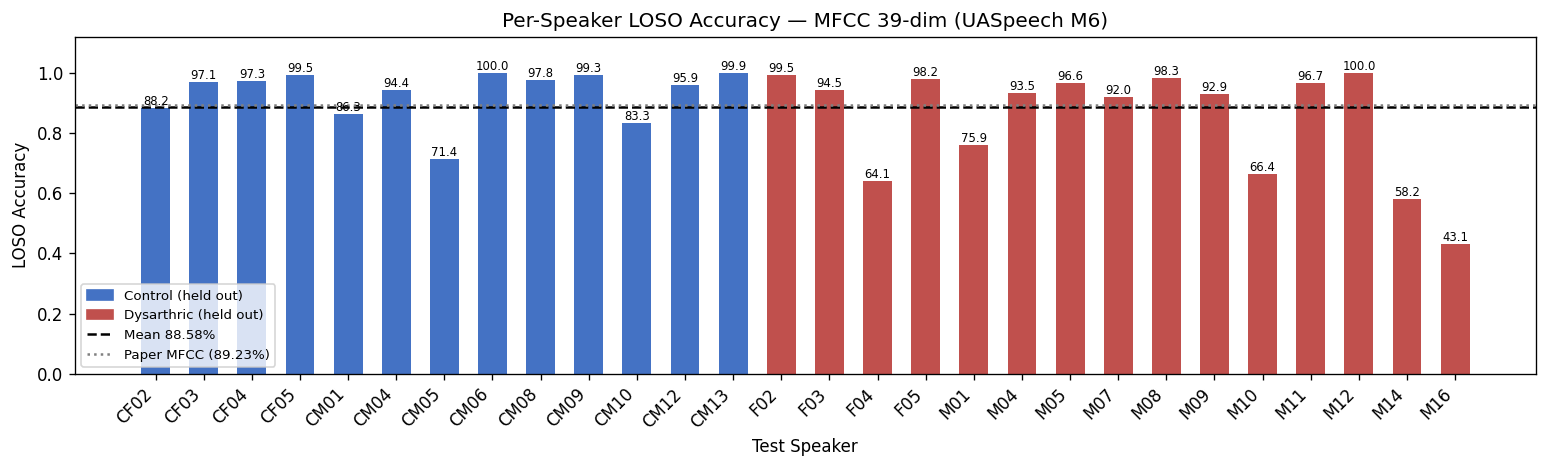

In [16]:
spk_list = unique_speakers
fig, ax = plt.subplots(figsize=(13, 4))
colours = ["#4472C4" if s.startswith("C") else "#C0504D" for s in spk_list]
ax.bar(spk_list, fold_accs, color=colours, width=0.6)
ax.axhline(fold_accs.mean(), color="black", linestyle="--",
           label=f"Mean {fold_accs.mean()*100:.2f}%")
ax.axhline(0.8923, color="grey", linestyle=":", label="Paper MFCC (89.23%)")
for i, (spk, acc) in enumerate(zip(spk_list, fold_accs)):
    ax.text(i, acc + 0.01, f"{acc*100:.1f}", ha="center", fontsize=7)
ax.set_ylabel("LOSO Accuracy")
ax.set_xlabel("Test Speaker")
ax.set_title("Per-Speaker LOSO Accuracy — MFCC 39-dim (UASpeech M6)")
ax.set_ylim(0, 1.12)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="#4472C4", label="Control (held out)"),
    Patch(color="#C0504D", label="Dysarthric (held out)"),
] + ax.get_legend_handles_labels()[0], fontsize=8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 6.  Confusion Matrix

Row-normalised (each row sums to 100 %) — values show recall per class.


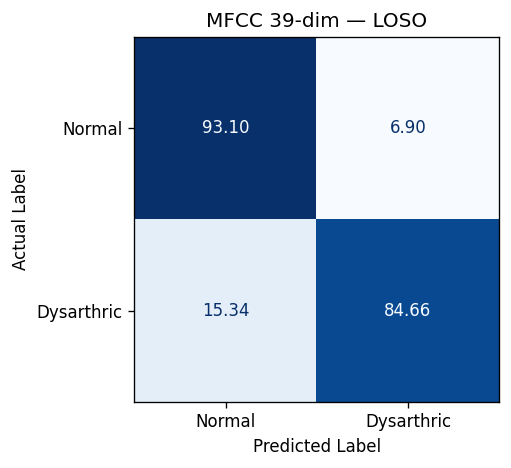

In [18]:
cm = confusion_matrix(all_true, all_pred, normalize="true")
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm * 100, display_labels=["Normal", "Dysarthric"]).plot(
    ax=ax, colorbar=False, cmap="Blues", values_format=".2f"
)
ax.set_title("MFCC 39-dim — LOSO")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()


## 7.  Observations

*(Fill in after running)*

- Paper reports **89.23 %** plain accuracy (mean over LOSO folds) for MFCC + SVM on UASpeech (M6).
- Our result (plain accuracy, mean per fold): **91.48 %**
- Sensitivity (dysarthric recall): paper = 0.86, ours = 0.89
- Specificity (normal recall):    paper = 0.93, ours = 0.95
- Compare with best wav2vec layer in `wav2vec_uaspeech.ipynb` (paper: wav2vec-1 = 93.95 % plain accuracy).